<a href="https://colab.research.google.com/github/23aiml21-cpu/URBAN-MOBILITY-PROJECT-/blob/main/Urban_mobility_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 3.3 MB/s eta 0:00:00


In [ ]:
import osmnx as ox
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

In [ ]:
ox.settings.timeout = 180
place = "Gandhi Nagar, Jaipur, Rajasthan, India"
G = ox.graph_from_address(place, dist=2000, network_type="drive")
for u, v, data in G.edges(data=True):
   speed_kph = data.get("speed_kph", 30)
   data["base_time"] = data["length"] / (speed_kph * 1000 / 60)
ox.save_graphml(G, "road_network.graphml")
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges saved")

3349 nodes, 8842 edges saved


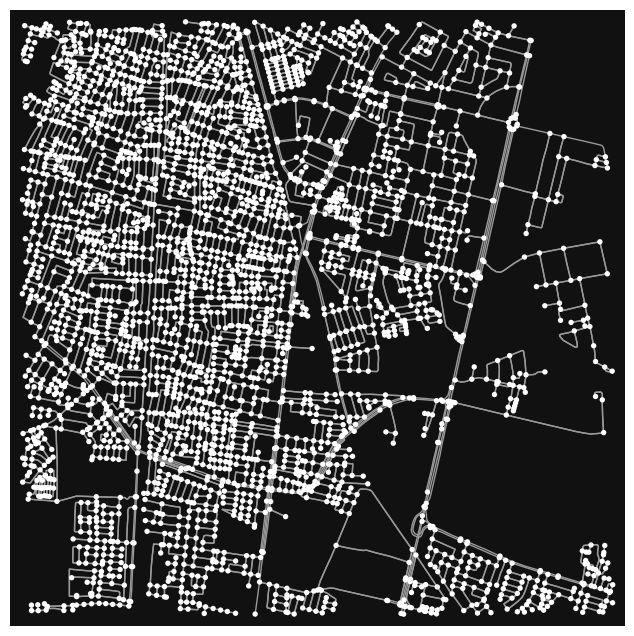

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [ ]:
ox.plot_graph(G)

In [ ]:
hours = np.arange(0, 24, 0.5)
rush_pattern = np.sin((hours - 8) * np.pi / 6) ** 2 + np.sin((hours - 18) * np.pi / 6) ** 2
congestion = 0.3 + 0.5 * rush_pattern + np.random.normal(0, 0.05, len(hours))

df = pd.DataFrame({"hour": hours, "congestion": np.clip(congestion, 0, 1)})
df.to_csv("sample_traffic_data.csv", index=False)
df.head()

,hour,congestion
0,0.0,0.732039
1,0.5,0.524153
2,1.0,0.518179
3,1.5,0.641804
4,2.0,0.666061


In [ ]:
class TrafficLSTM(nn.Module):
      def __init__(self, input_size=1, hidden_size=32, num_layers=1):
            super().__init__()
            self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
            self.fc = nn.Linear(hidden_size, 1)
      def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

In [ ]:
seq_len = 6
values = df["congestion"].values
X = [values[i:i+seq_len] for i in range(len(values) - seq_len)]
y = [values[i+seq_len] for i in range(len(values) - seq_len)]
X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)


model = TrafficLSTM()
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

for epoch in range(30):
  optimizer.zero_grad()
  pred = model(X)
  loss = loss_fn(pred, y)
  loss.backward()
  optimizer.step()
  if epoch % 5 == 0:
    print(f"Epoch {epoch}, Loss: {loss.item():.4f}")
torch.save(model.state_dict(), "traffic_lstm.pt")
print("Model saved.")

/tmp/ipykernel_973/3207926563.py:5: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)


Epoch 0, Loss: 0.5372
Epoch 5, Loss: 0.0306
Epoch 10, Loss: 0.0267
Epoch 15, Loss: 0.0444
Epoch 20, Loss: 0.0270
Epoch 25, Loss: 0.0261
Model saved.


In [ ]:
ALPHA, BETA = 0.6, 0.4
def predict_edge_weights(G, model):
  weights = {}
  sample_seq = torch.tensor([[0.4],[0.5],[0.6],[0.55],[0.5],[0.45]]).unsqueeze(0)
  predicted = model(sample_seq).item()
  for u, v, data in G.edges(data=True):
    weights[(u, v)] = predicted * data["base_time"]
  return weights
def compute_astar_route(G, source, dest, predicted_weights):
  for u, v, data in G.edges(data=True):
    predicted = predicted_weights.get((u, v), data["base_time"])
    data["cost"] = ALPHA * data["length"] + BETA * predicted
  path = nx.astar_path(G, source, dest, weight="cost")
  total_eta = sum(G[u][v][0]["cost"] for u, v in zip(path[:-1], path[1:]))
  return path, total_eta

Route: [316674391, 3782908839, 3782908840, 3782908824, 3782908817, 11209374987, 11209374988, 4733487576, 3782908444, 3734362779, 3782908429, 4733487588, 3734362778, 1753726606, 3782908404, 1753726602, 3782908391, 1753726599, 14063322196, 1753726594, 3782908372, 3782908369, 2392620199, 1753726575, 11224196247, 3785868795, 11224196248, 5490770642, 11224212178, 2392620210, 11224171323, 2392620232, 1753726581, 1753726580, 4733958023, 3784719091, 4720022145, 4733958033, 318621448, 3782869214, 11752577501, 2392683796, 320835885, 11370385118, 12649692801, 11209548139, 316742799, 8628667210, 2392613634, 6880321484, 316918929]
Predicted ETA: 1601.1 minutes


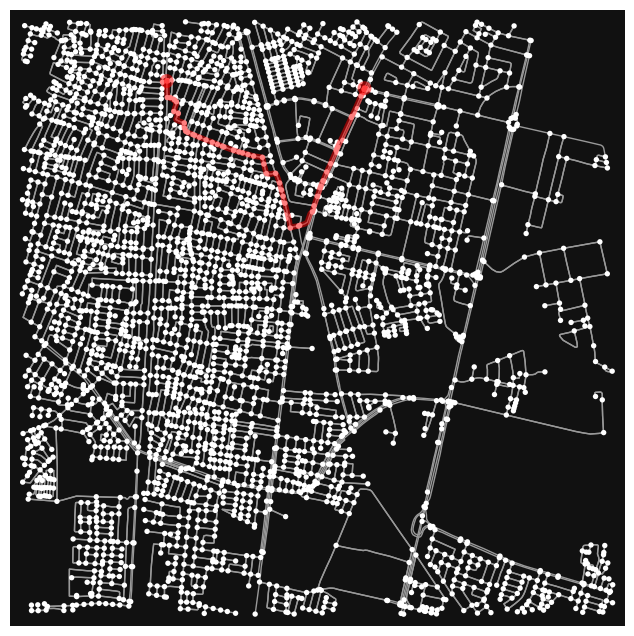

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [ ]:
node_list = list(G.nodes)
source, destination = node_list[0], node_list[20]

weights = predict_edge_weights(G, model)
path, eta = compute_astar_route(G, source, destination, weights)
print("Route:", path)
print("Predicted ETA:", round(eta, 1), "minutes")

ox.plot_graph_route(G, path, route_color="r", route_linewidth=4)

In [ ]:
!pip install fastapi uvicorn pyngrok nest_asyncio


In [ ]:
def get_node_from_place(place_name):
    lat, lon = ox.geocode(place_name)
    node = ox.distance.nearest_nodes(G, lon, lat)
    return node

# अपने demo area की असली जगहों के नाम डालो
point_A = get_node_from_place("Gandhi Nagar, Jaipur, Rajasthan")
point_B = get_node_from_place("Tonk Road, Jaipur, Rajasthan")

print("Point A node:", point_A)
print("Point B node:", point_B)

Point A node: 3710888280
Point B node: 3783217169


Route: [3710888280, 3710888248, 7299085350, 7299085354, 7299085355, 7299085357, 7299085358, 3785868177, 3785868176, 3785868148, 8637663632, 8637663629, 8637663628, 3785868145, 8075691579, 316800708, 4720224241, 1753714624, 3787810253, 14076722441, 3785992769, 14076722445, 3783097716, 3783097719, 3783179004, 3787810228, 3787810249, 3783097728, 3787810250, 3787810202, 3787810002, 3787809966, 3787809903, 3787809875, 3787809848, 3787809823, 3787809787, 3787809780, 3787809729, 3787809712, 3787809663, 3787809656, 3787809651, 3787809634, 3787809627, 3783217169]
Predicted ETA: 2040.2 minutes


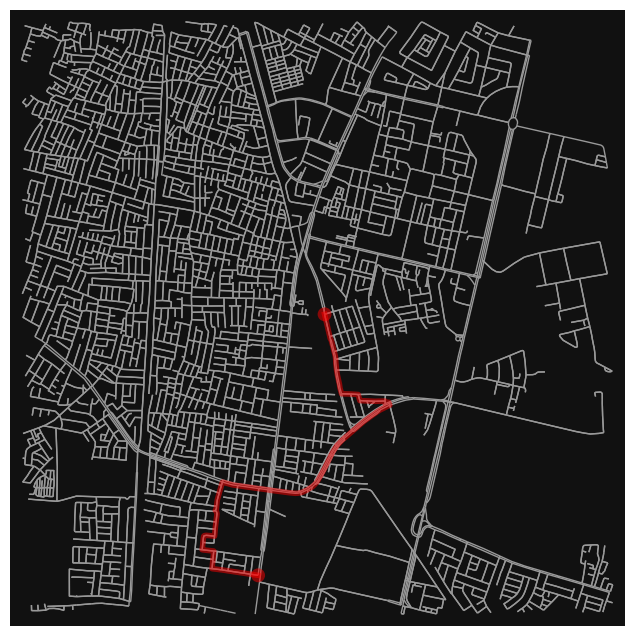

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [ ]:
weights = predict_edge_weights(G, model)
path, eta = compute_astar_route(G, point_A, point_B, weights)

print("Route:", path)
print("Predicted ETA:", round(eta, 1), "minutes")

ox.plot_graph_route(G, path, route_color="r", route_linewidth=4, node_size=0)

In [ ]:
from fastapi import FastAPI
from pydantic import BaseModel
import nest_asyncio, uvicorn
from pyngrok import ngrok

ngrok.set_auth_token("3KVE2cr8443VtJwXSymD1VbzkRL_6WRhy3ELbkvxy3fZr64d6")

app = FastAPI()

class RouteRequest(BaseModel):
    source: int
    destination: int

@app.post("/route")
def get_route(req: RouteRequest):
    weights = predict_edge_weights(G, model)
    path, eta = compute_astar_route(G, req.source, req.destination, weights)
    return {"route": path, "eta_minutes": round(eta, 1)}

nest_asyncio.apply()
public_url = ngrok.connect(8000)
print("Your live link:", public_url)

config = uvicorn.Config(app=app, port=8000)
server = uvicorn.Server(config)
await server.serve()

Your live link: NgrokTunnel: "https://prorate-undrilled-zippy.ngrok-free.dev" -> "http://localhost:8000"


INFO:     Started server process [973]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     2409:40d4:101b:1051:dcb:bc45:51d3:ba94:0 - "GET / HTTP/1.1" 404 Not Found
INFO:     2409:40d4:101b:1051:dcb:bc45:51d3:ba94:0 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     2409:40d4:101b:1051:dcb:bc45:51d3:ba94:0 - "GET /docs HTTP/1.1" 200 OK
INFO:     2409:40d4:101b:1051:dcb:bc45:51d3:ba94:0 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     2409:40d4:101b:1051:dcb:bc45:51d3:ba94:0 - "POST /route HTTP/1.1" 200 OK
